In [1]:
import sys, os, datetime, importlib, tqdm

import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

import torchvision
read = torchvision.datasets.CIFAR10(root='ds_CIFAR10', train=True, download=False)
read = torch.as_tensor(read.data[:200]).clone()

epoch 999 - lr : 4.991695277540097e-06 - loss : 207.87924194335938: 100%|███████████| 1000/1000 [07:46<00:00,  2.14it/s]

tensor(207.8792, device='cuda:0')


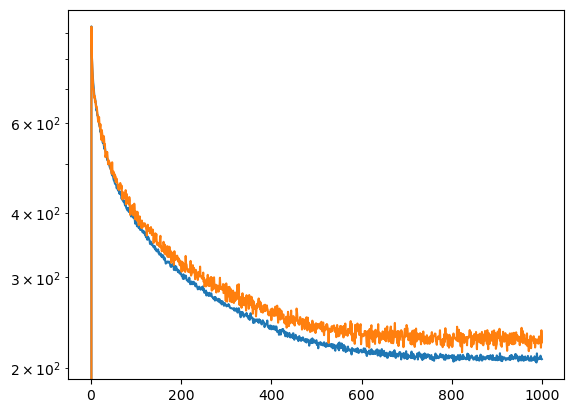

In [12]:
import nn_util; importlib.reload(nn_util)
import nn_tf; importlib.reload(nn_tf)
import nn_reg; importlib.reload(nn_reg)

feed = read[:,:16,:16,0].to(torch.float32)/255
feed = feed.flatten(1).cuda()[:,None,:]

#model = nn_ebm.dynEBAM(train.flatten(1).shape[-1], 128, lr=0.007, r_sigma=1e-4, dist=nn_ebm.dist_dp).to(torch.float32)
model = nn_tf.r2PA_Transformer(h=16, c=1, dim=feed.shape[-1], hdim=32, layers=12, activation='sigmoid', is_residual=False)
wrapper = nn_reg.VMWrapper(model, feed.shape[-1], n=32, T=1).to('cuda', torch.float32)

# optimizer
loss_hist, v_loss_hist = [0], [0]
opt = torch.optim.AdamW(wrapper.parameters(), lr=0.0025, fused=True)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=10, factor=0.9)
d_train, d_valid = feed[:-feed.shape[0]//10], feed[-feed.shape[0]//10:]
# loop
t_loop = tqdm.tqdm(range(1000))
for i in t_loop:
    opt.zero_grad()
    loss    = wrapper.train(d_train)
    v_loss  = wrapper.train(d_valid, do_backprop=False).detach()
    opt.step(); sched.step(v_loss)
    v_loss_hist.append(v_loss.item()); loss_hist.append(loss.detach().item())
    t_loop.set_description(f'epoch {i} - lr : {opt.param_groups[0]['lr']} - loss : {loss_hist[-1]}')
print(loss)
plt.plot(loss_hist); plt.plot(v_loss_hist); plt.yscale('log'); plt.show()

In [91]:
#torch.zeros_like(torch.zeros(3), requires_grad=True)


device(type='cuda', index=0)

corrupted image MSE 0.2942362427711487
regenerated image MSE 0.11665411293506622


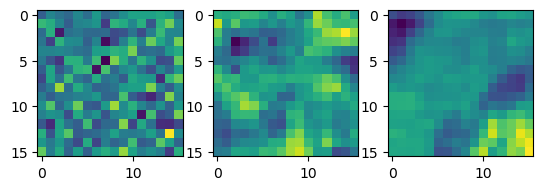

corrupted image MSE 0.33492419123649597
regenerated image MSE 0.1379380226135254


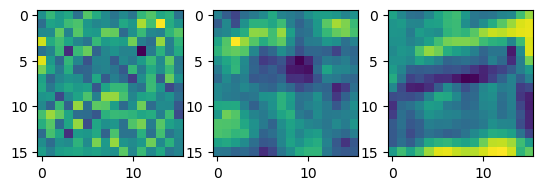

corrupted image MSE 0.4002932906150818
regenerated image MSE 0.20464330911636353


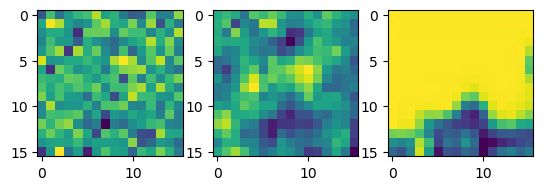

corrupted image MSE 0.26893171668052673
regenerated image MSE 0.0778125524520874


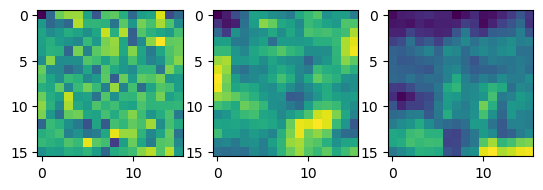

In [371]:
import nn_reg; importlib.reload(nn_reg)
sampler = nn_reg.VMSampler_DPS_Momentum(wrapper)
#sampler = nn_reg.VMSampler_Momentum(wrapper)
#sampler = wrapper.get_sampler(kind='cond')
sampler.n = 64
sampler.T = 1

feed1 = d_train[:4]
with torch.no_grad():
    broke = 0.5*feed1 + 0.5*torch.randn_like(feed1)
    result = sampler.forward(broke.repeat(1,1,1), 0.8, 1)#, lambda x: (x + torch.randn_like(x))*0.5)
    
    result = result.mean(1).detach().cpu()

vs = int(feed.shape[-1]**0.5)
for i in range(result.shape[0]):
    plt.subplot(1,3,1); plt.imshow(broke[i].cpu().view(vs,vs));
    plt.subplot(1,3,2); plt.imshow(result[i].cpu().view(vs,vs));
    plt.subplot(1,3,3); plt.imshow(feed1[i].cpu().view(vs,vs))
    print('corrupted image MSE', (feed1[i].cpu() - broke[i].cpu()).pow(2).mean().item())
    print('regenerated image MSE', (feed1[i].cpu() - result[i].cpu()).pow(2).mean().item())
    plt.show()
    